<a href="https://colab.research.google.com/github/torcodex/House-Price-Predictor/blob/main/Improved_House_Price_Predictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [208]:
# !pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 37.7 MB/s  0:00:02


In [209]:
# Load all the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.metrics import mean_squared_error, r2_score,mean_absolute_error, root_mean_squared_error, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from scipy.stats import f_oneway
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

In [4]:
# Load the datasets
df = pd.read_csv('/content/AmesHousing.csv')
df

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,2926,923275080,80,RL,37.0,7937,Pave,NaN,IR1,Lvl,...,0,NaN,GdPrv,NaN,0,3,2006,WD,Normal,142500
2926,2927,923276100,20,RL,NaN,8885,Pave,NaN,IR1,Low,...,0,NaN,MnPrv,NaN,0,6,2006,WD,Normal,131000
2927,2928,923400125,85,RL,62.0,10441,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,Shed,700,7,2006,WD,Normal,132000
2928,2929,924100070,20,RL,77.0,10010,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2006,WD,Normal,170000


In [5]:
# Check for the null values
df.isna().sum().sum()

np.int64(15749)

In [6]:
df.shape

(2930, 82)

In [7]:
# Check for the duplicated values
df.duplicated().sum()

np.int64(0)

In [8]:
dels = (df.isna().mean() * 100).sort_values(ascending=False)
dels[dels>0]

,0
Pool QC,99.556314
Misc Feature,96.382253
Alley,93.242321
Fence,80.477816
Mas Vnr Type,60.580205
Fireplace Qu,48.532423
Lot Frontage,16.723549
Garage Qual,5.426621
Garage Yr Blt,5.426621
Garage Cond,5.426621


In [9]:
df.columns

Index(['Order', 'PID', 'MS SubClass', 'MS Zoning', 'Lot Frontage', 'Lot Area',
       'Street', 'Alley', 'Lot Shape', 'Land Contour', 'Utilities',
       'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1',
       'Condition 2', 'Bldg Type', 'House Style', 'Overall Qual',
       'Overall Cond', 'Year Built', 'Year Remod/Add', 'Roof Style',
       'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type',
       'Mas Vnr Area', 'Exter Qual', 'Exter Cond', 'Foundation', 'Bsmt Qual',
       'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin SF 1',
       'BsmtFin Type 2', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF',
       'Heating', 'Heating QC', 'Central Air', 'Electrical', '1st Flr SF',
       '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Bsmt Full Bath',
       'Bsmt Half Bath', 'Full Bath', 'Half Bath', 'Bedroom AbvGr',
       'Kitchen AbvGr', 'Kitchen Qual', 'TotRms AbvGrd', 'Functional',
       'Fireplaces', 'Fireplace Qu', 'Garage Type', 'Garage Yr Blt',
      

In [10]:
df.drop(columns=['Pool QC','Order','Misc Feature','Alley','Fence','Mas Vnr Type','Fireplace Qu','PID'], inplace=True)

In [11]:
no_garage = df["Garage Type"].isna()
no_garage.sum()

np.int64(157)

In [12]:
df['SalePrice'].isna().sum()

np.int64(0)

In [13]:
nuls = df.isna().sum()
nuls[nuls>0]

,0
Lot Frontage,490
Mas Vnr Area,23
Bsmt Qual,80
Bsmt Cond,80
Bsmt Exposure,83
BsmtFin Type 1,80
BsmtFin SF 1,1
BsmtFin Type 2,81
BsmtFin SF 2,1
Bsmt Unf SF,1


In [14]:
# Extract basement-related columns
basement_cols = [
    'Bsmt Qual',
    'Bsmt Cond',
    'Bsmt Exposure',
    'BsmtFin Type 1',
    'BsmtFin SF 1',
    'BsmtFin Type 2',
    'BsmtFin SF 2',
    'Bsmt Unf SF',
    'Total Bsmt SF',
    'Bsmt Full Bath',
    'Bsmt Half Bath'
]

# Display basement columns
df[basement_cols].head()

,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath
0,TA,Gd,Gd,BLQ,639.0,Unf,0.0,441.0,1080.0,1.0,0.0
1,TA,TA,No,Rec,468.0,LwQ,144.0,270.0,882.0,0.0,0.0
2,TA,TA,No,ALQ,923.0,Unf,0.0,406.0,1329.0,0.0,0.0
3,TA,TA,No,ALQ,1065.0,Unf,0.0,1045.0,2110.0,1.0,0.0
4,Gd,TA,No,GLQ,791.0,Unf,0.0,137.0,928.0,0.0,0.0


In [15]:
# Count missing values in basement columns
df[basement_cols].isnull().sum()

,0
Bsmt Qual,80
Bsmt Cond,80
Bsmt Exposure,83
BsmtFin Type 1,80
BsmtFin SF 1,1
BsmtFin Type 2,81
BsmtFin SF 2,1
Bsmt Unf SF,1
Total Bsmt SF,1
Bsmt Full Bath,2


In [16]:
df[basement_cols].dtypes

,0
Bsmt Qual,object
Bsmt Cond,object
Bsmt Exposure,object
BsmtFin Type 1,object
BsmtFin SF 1,float64
BsmtFin Type 2,object
BsmtFin SF 2,float64
Bsmt Unf SF,float64
Total Bsmt SF,float64
Bsmt Full Bath,float64


In [17]:
# Check whether every basement-related column is null for each row
no_basement_mask = (df[basement_cols].isnull().all(axis=1))

# Count the number of houses with all basement columns missing
print("Houses with all basement columns null:", no_basement_mask.sum())

# Display those rows
df.loc[no_basement_mask, basement_cols]

Houses with all basement columns null: 1


,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath
1341,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [18]:
# Categorical basement columns
basement_cat_cols = [
    'Bsmt Qual',
    'Bsmt Cond',
    'Bsmt Exposure',
    'BsmtFin Type 1',
    'BsmtFin Type 2'
]

# Numerical basement columns
basement_num_cols = [
    'BsmtFin SF 1',
    'BsmtFin SF 2',
    'Bsmt Unf SF',
    'Total Bsmt SF',
    'Bsmt Full Bath',
    'Bsmt Half Bath'
]

In [19]:
for col in basement_cat_cols:
    print(f"{col} : {df[col].unique()}\n")

Bsmt Qual : ['TA' 'Gd' 'Ex' nan 'Fa' 'Po']

Bsmt Cond : ['Gd' 'TA' nan 'Po' 'Fa' 'Ex']

Bsmt Exposure : ['Gd' 'No' 'Mn' 'Av' nan]

BsmtFin Type 1 : ['BLQ' 'Rec' 'ALQ' 'GLQ' 'Unf' 'LwQ' nan]

BsmtFin Type 2 : ['Unf' 'LwQ' 'BLQ' 'Rec' nan 'GLQ' 'ALQ']



In [20]:
# Fill categorical columns with 'None'
df.loc[no_basement_mask, basement_cat_cols] = 'None'

# Fill numerical columns with 0
df.loc[no_basement_mask, basement_num_cols] = 0

In [21]:
# Check missing values after filling
print(df[basement_cols].isnull().sum())

# Check whether any rows still have all basement columns null
print(
    "Rows with all basement columns still null:",
    df[basement_cols].isnull().all(axis=1).sum()
)

Bsmt Qual         79
Bsmt Cond         79
Bsmt Exposure     82
BsmtFin Type 1    79
BsmtFin SF 1       0
BsmtFin Type 2    80
BsmtFin SF 2       0
Bsmt Unf SF        0
Total Bsmt SF      0
Bsmt Full Bath     1
Bsmt Half Bath     1
dtype: int64
Rows with all basement columns still null: 0


In [22]:
garage_cols = [
    'Garage Type',
    'Garage Yr Blt',
    'Garage Finish',
    'Garage Cars',
    'Garage Area',
    'Garage Qual',
    'Garage Cond'
]

garage_cat_cols = [
    'Garage Type',
    'Garage Finish',
    'Garage Qual',
    'Garage Cond'
]

garage_num_cols = [
    'Garage Yr Blt',
    'Garage Cars',
    'Garage Area'
]

In [23]:
masonry_num_cols = [
    'Mas Vnr Area'
]

In [24]:
masonry_no_mask = df[masonry_num_cols].isnull().all(axis=1)

print("Rows with all Masonry columns null:",
      masonry_no_mask.sum())

df.loc[masonry_no_mask, masonry_num_cols]

Rows with all Masonry columns null: 23


,Mas Vnr Area
55,NaN
484,NaN
517,NaN
538,NaN
867,NaN
1095,NaN
1119,NaN
1122,NaN
1127,NaN
1184,NaN


In [25]:
masonry_partial_mask = (
    df[masonry_num_cols].isnull().any(axis=1) &
    ~masonry_no_mask
)

print("Rows with partial Masonry nulls:",
      masonry_partial_mask.sum())

df.loc[masonry_partial_mask, masonry_num_cols]

Rows with partial Masonry nulls: 0


,Mas Vnr Area


In [26]:
df.loc[masonry_no_mask, masonry_num_cols] = 0

In [27]:
pool_num_cols = [
    'Pool Area'
]

In [28]:
pool_no_mask = df[pool_num_cols].isnull().all(axis=1)

print("Rows with all Pool columns null:",
      pool_no_mask.sum())

df.loc[pool_no_mask, pool_num_cols]

Rows with all Pool columns null: 0


,Pool Area


In [29]:
pool_partial_mask = (
    df[pool_num_cols].isnull().any(axis=1) &
    ~pool_no_mask
)

print("Rows with partial Pool nulls:",
      pool_partial_mask.sum())

df.loc[pool_partial_mask, pool_num_cols]

Rows with partial Pool nulls: 0


,Pool Area


In [30]:
df.loc[pool_no_mask, pool_num_cols] = 0

In [31]:
nuls = df.isna().sum()
nuls[nuls>0]

,0
Lot Frontage,490
Bsmt Qual,79
Bsmt Cond,79
Bsmt Exposure,82
BsmtFin Type 1,79
BsmtFin Type 2,80
Electrical,1
Bsmt Full Bath,1
Bsmt Half Bath,1
Garage Type,157


In [32]:
df.shape

(2930, 74)

In [33]:
dels = (df.isna().mean() * 100).sort_values(ascending=False)
dels[dels>0]

,0
Lot Frontage,16.723549
Garage Qual,5.426621
Garage Yr Blt,5.426621
Garage Finish,5.426621
Garage Cond,5.426621
Garage Type,5.358362
Bsmt Exposure,2.798635
BsmtFin Type 2,2.730375
Bsmt Qual,2.696246
BsmtFin Type 1,2.696246


In [34]:
groups = {
    'Garage': garage_cols,
    'Masonry': masonry_num_cols,
    'Pool': pool_num_cols
}

for group_name, columns in groups.items():

    print(f"\n{group_name}")
    print("-" * 40)

    print("Remaining null values:")
    print(df[columns].isnull().sum())

    print(
        "Rows with all columns null:",
        df[columns].isnull().all(axis=1).sum()
    )


Garage
----------------------------------------
Remaining null values:
Garage Type      157
Garage Yr Blt    159
Garage Finish    159
Garage Cars        1
Garage Area        1
Garage Qual      159
Garage Cond      159
dtype: int64
Rows with all columns null: 0

Masonry
----------------------------------------
Remaining null values:
Mas Vnr Area    0
dtype: int64
Rows with all columns null: 0

Pool
----------------------------------------
Remaining null values:
Pool Area    0
dtype: int64
Rows with all columns null: 0


In [35]:
garage_type_null = df['Garage Type'].isnull()

df.loc[
    garage_type_null,
    garage_cols
].head(20)

,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond
27,NaN,NaN,NaN,0.0,0.0,NaN,NaN
119,NaN,NaN,NaN,0.0,0.0,NaN,NaN
125,NaN,NaN,NaN,0.0,0.0,NaN,NaN
129,NaN,NaN,NaN,0.0,0.0,NaN,NaN
130,NaN,NaN,NaN,0.0,0.0,NaN,NaN
170,NaN,NaN,NaN,0.0,0.0,NaN,NaN
171,NaN,NaN,NaN,0.0,0.0,NaN,NaN
186,NaN,NaN,NaN,0.0,0.0,NaN,NaN
203,NaN,NaN,NaN,0.0,0.0,NaN,NaN
206,NaN,NaN,NaN,0.0,0.0,NaN,NaN


In [36]:
no_garage_mask = (
    df['Garage Type'].isnull() &
    (df['Garage Cars'] == 0) &
    (df['Garage Area'] == 0)
)

# Fill categorical columns
df.loc[no_garage_mask, garage_cat_cols] = 'None'

# Fill Garage Year Built
df.loc[no_garage_mask, 'Garage Yr Blt'] = 0

In [37]:
nuls = df.isna().sum()
nuls[nuls>0]

,0
Lot Frontage,490
Bsmt Qual,79
Bsmt Cond,79
Bsmt Exposure,82
BsmtFin Type 1,79
BsmtFin Type 2,80
Electrical,1
Bsmt Full Bath,1
Bsmt Half Bath,1
Garage Yr Blt,2


In [38]:
df['Lot Frontage'] = df['Lot Frontage'].fillna(df.groupby('Neighborhood')['Lot Frontage'].transform('median'))

In [39]:
df[df['Lot Frontage'].isna()]

,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,...,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
2256,120,RM,NaN,9763,Pave,IR1,Lvl,AllPub,Inside,Gtl,...,0,0,0,0,0,9,2007,WD,Normal,330000
2788,160,RH,NaN,3612,Pave,IR1,Lvl,AllPub,Inside,Gtl,...,0,0,0,0,0,6,2006,WD,Normal,137000
2892,120,RM,NaN,8239,Pave,IR1,Lvl,AllPub,Inside,Gtl,...,0,0,0,0,0,11,2006,WD,Normal,230000


In [40]:
df.loc[
    df['Lot Frontage'].isnull(),
    ['Neighborhood', 'Lot Frontage']
]

,Neighborhood,Lot Frontage
2256,GrnHill,NaN
2788,Landmrk,NaN
2892,GrnHill,NaN


In [41]:
nuls = df.isna().sum()
nuls[nuls>0]

,0
Lot Frontage,3
Bsmt Qual,79
Bsmt Cond,79
Bsmt Exposure,82
BsmtFin Type 1,79
BsmtFin Type 2,80
Electrical,1
Bsmt Full Bath,1
Bsmt Half Bath,1
Garage Yr Blt,2


In [42]:
df.groupby('Neighborhood')['Lot Frontage'].median()

,Lot Frontage
Neighborhood,
Blmngtn,43.0
Blueste,24.0
BrDale,21.0
BrkSide,51.0
ClearCr,80.5
CollgCr,70.0
Crawfor,70.0
Edwards,65.0
Gilbert,64.0


In [43]:
overall_median = df['Lot Frontage'].median()

df['Lot Frontage'] = df['Lot Frontage'].fillna(overall_median)

In [44]:
for col in basement_cat_cols:

    print(f"\n{col}")

    print(
        "Missing values:",
        df[col].isnull().sum()
    )

    print(
        "Missing values where basement area is zero:",
        (df[col].isnull() & no_basement_mask).sum()
    )


Bsmt Qual
Missing values: 79
Missing values where basement area is zero: 0

Bsmt Cond
Missing values: 79
Missing values where basement area is zero: 0

Bsmt Exposure
Missing values: 82
Missing values where basement area is zero: 0

BsmtFin Type 1
Missing values: 79
Missing values where basement area is zero: 0

BsmtFin Type 2
Missing values: 80
Missing values where basement area is zero: 0


In [45]:
garage_null_mask = df[garage_cols].isnull().any(axis=1)

df.loc[
    garage_null_mask,
    garage_cols
]

,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond
1356,Detchd,NaN,NaN,1.0,360.0,NaN,NaN
2236,Detchd,NaN,NaN,NaN,NaN,NaN,NaN


In [46]:
nuls = df.isna().sum()
nuls[nuls>0]

,0
Bsmt Qual,79
Bsmt Cond,79
Bsmt Exposure,82
BsmtFin Type 1,79
BsmtFin Type 2,80
Electrical,1
Bsmt Full Bath,1
Bsmt Half Bath,1
Garage Yr Blt,2
Garage Finish,2


In [47]:
df.dropna(subset=['Electrical','Garage Yr Blt'], inplace=True)

In [48]:
nuls = df.isna().sum()
nuls[nuls>0]

,0
Bsmt Qual,79
Bsmt Cond,79
Bsmt Exposure,82
BsmtFin Type 1,79
BsmtFin Type 2,80
Bsmt Full Bath,1
Bsmt Half Bath,1


In [49]:
no_basement_mask = df['Total Bsmt SF'] == 0

print("Houses without basements:", no_basement_mask.sum())

Houses without basements: 80


In [50]:
for col in basement_cat_cols:

    print(f"\n{col}")

    print(
        "Missing values in houses without basement:",
        (df[col].isnull() & no_basement_mask).sum()
    )

    print(
        "Missing values in houses with basement:",
        (df[col].isnull() & ~no_basement_mask).sum()
    )


Bsmt Qual
Missing values in houses without basement: 79
Missing values in houses with basement: 0

Bsmt Cond
Missing values in houses without basement: 79
Missing values in houses with basement: 0

Bsmt Exposure
Missing values in houses without basement: 79
Missing values in houses with basement: 3

BsmtFin Type 1
Missing values in houses without basement: 79
Missing values in houses with basement: 0

BsmtFin Type 2
Missing values in houses without basement: 79
Missing values in houses with basement: 1


In [51]:
df.loc[
    df[basement_cat_cols].isnull().any(axis=1),
    ['Total Bsmt SF'] + basement_cat_cols
]

,Total Bsmt SF,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin Type 2
66,1595.0,Gd,TA,NaN,Unf,Unf
83,0.0,NaN,NaN,NaN,NaN,NaN
154,0.0,NaN,NaN,NaN,NaN,NaN
206,0.0,NaN,NaN,NaN,NaN,NaN
243,0.0,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...
2744,0.0,NaN,NaN,NaN,NaN,NaN
2779,936.0,Gd,TA,NaN,Unf,Unf
2879,0.0,NaN,NaN,NaN,NaN,NaN
2892,0.0,NaN,NaN,NaN,NaN,NaN


In [52]:
no_basement_mask = df['Total Bsmt SF'] == 0

df.loc[
    no_basement_mask, basement_cat_cols
] = df.loc[
    no_basement_mask, basement_cat_cols
].fillna('None')

In [53]:
nuls = df.isna().sum()
nuls[nuls>0]

,0
Bsmt Exposure,3
BsmtFin Type 2,1
Bsmt Full Bath,1
Bsmt Half Bath,1


In [54]:
print('Bsmt Half Bath unique:', df['Bsmt Half Bath'].unique())
print('Bsmt Full Bath unique:', df['Bsmt Full Bath'].unique())

Bsmt Half Bath unique: [ 0.  1. nan  2.]
Bsmt Full Bath unique: [ 1.  0.  2.  3. nan]


In [55]:
df['BsmtFin Type 1'] = df['BsmtFin Type 1'].fillna(df['BsmtFin Type 1'].mode()[0])
df['BsmtFin Type 2'] = df['BsmtFin Type 2'].fillna(df['BsmtFin Type 2'].mode()[0])
df['Bsmt Half Bath'] = df['Bsmt Half Bath'].fillna(df['Bsmt Half Bath'].mode()[0])
df['Bsmt Full Bath'] = df['Bsmt Full Bath'].fillna(df['Bsmt Full Bath'].mode()[0])
df['Bsmt Exposure'] = df['Bsmt Exposure'].fillna(df['Bsmt Exposure'].mode()[0])

In [56]:
for col in df.columns:
    print(f'The data type of {col} is {df[col].dtype}')
    print()
    print(f'The unique values of {col} are {df[col].unique()}')
    print('#####################################################################################')

The data type of MS SubClass is int64

The unique values of MS SubClass are [ 20  60 120  50  85 160  80  30  90 190  45  70  75  40 180 150]
#####################################################################################
The data type of MS Zoning is object

The unique values of MS Zoning are ['RL' 'RH' 'FV' 'RM' 'C (all)' 'I (all)' 'A (agr)']
#####################################################################################
The data type of Lot Frontage is float64

The unique values of Lot Frontage are [141.   80.   81.   93.   74.   78.   41.   43.   39.   60.   75.   64.
  63.   85.   47.  152.   88.  140.  105.   72.5  73.   65.   70.   26.
  21.   53.   24.  102.   98.   83.   94.   95.   90.   79.  100.   44.
 110.   61.   36.   67.  108.   59.   92.   58.   56.   72.   84.   76.
  50.   55.   68.  107.   25.   30.   57.   40.   77.  120.  137.   87.
 119.   96.   71.   69.   51.   52.   80.5  54.   86.  124.   82.   38.
  48.   89.   66.   45.   35.  129.   31.   42.  

In [57]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
MS SubClass,2927.0,57.374445,42.657162,20.0,20.0,50.0,70.0,190.0
Lot Frontage,2927.0,69.474889,21.725238,21.0,60.0,70.0,80.0,313.0
Lot Area,2927.0,10149.136317,7883.935500,1300.0,7439.0,9439.0,11556.0,215245.0
Overall Qual,2927.0,6.095661,1.411458,1.0,5.0,6.0,7.0,10.0
Overall Cond,2927.0,5.562351,1.111115,1.0,5.0,5.0,6.0,9.0
Year Built,2927.0,1971.381961,30.219582,1872.0,1954.0,1973.0,2001.0,2010.0
Year Remod/Add,2927.0,1984.254185,20.864951,1950.0,1965.0,1993.0,2004.0,2010.0
Mas Vnr Area,2927.0,101.200547,178.696749,0.0,0.0,0.0,163.0,1600.0
BsmtFin SF 1,2927.0,442.677827,455.719544,0.0,0.0,370.0,734.5,5644.0
BsmtFin SF 2,2927.0,49.756406,169.221285,0.0,0.0,0.0,0.0,1526.0


In [58]:
df.shape

(2927, 74)

In [59]:
df.drop(
    df.index[df['Garage Yr Blt'] == 2207],
    inplace=True
)

In [60]:
df[df['Garage Yr Blt']==2207]['Garage Yr Blt']

,Garage Yr Blt


In [61]:
df.shape

(2926, 74)

In [62]:
suspected_cols = [
    'Lot Frontage',
    'Lot Area',
    'Mas Vnr Area',
    'BsmtFin SF 1',
    'BsmtFin SF 2',
    'Total Bsmt SF',
    '1st Flr SF',
    'Low Qual Fin SF',
    'Gr Liv Area',
    'Bedroom AbvGr',
    'TotRms AbvGrd',
    'Garage Area',
    'Wood Deck SF',
    'Open Porch SF',
    'Enclosed Porch',
    '3Ssn Porch',
    'Screen Porch',
    'Pool Area',
    'Misc Val',
    'SalePrice'
]

outlier_results = []

for col in suspected_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_count = (
        (df[col] < lower) |
        (df[col] > upper)
    ).sum()

    outlier_results.append({
        'Column': col,
        'Lower Limit': lower,
        'Upper Limit': upper,
        'Outlier Count': outlier_count
    })

outlier_df = pd.DataFrame(outlier_results)

outlier_df.sort_values(
    by='Outlier Count',
    ascending=False
)

,Column,Lower Limit,Upper Limit,Outlier Count
14,Enclosed Porch,0.000,0.000,457
4,BsmtFin SF 2,0.000,0.000,351
16,Screen Porch,0.000,0.000,256
0,Lot Frontage,30.000,110.000,206
2,Mas Vnr Area,-244.500,407.500,203
13,Open Porch SF,-105.000,175.000,159
19,SalePrice,3500.000,339500.000,137
1,Lot Area,1262.250,17732.250,127
5,Total Bsmt SF,30.250,2064.250,124
18,Misc Val,0.000,0.000,102


In [63]:
num_col = []

for col in df.columns:
    if df[col].dtype != 'object':
        num_col.append(col)

num_col

['MS SubClass',
 'Lot Frontage',
 'Lot Area',
 'Overall Qual',
 'Overall Cond',
 'Year Built',
 'Year Remod/Add',
 'Mas Vnr Area',
 'BsmtFin SF 1',
 'BsmtFin SF 2',
 'Bsmt Unf SF',
 'Total Bsmt SF',
 '1st Flr SF',
 '2nd Flr SF',
 'Low Qual Fin SF',
 'Gr Liv Area',
 'Bsmt Full Bath',
 'Bsmt Half Bath',
 'Full Bath',
 'Half Bath',
 'Bedroom AbvGr',
 'Kitchen AbvGr',
 'TotRms AbvGrd',
 'Fireplaces',
 'Garage Yr Blt',
 'Garage Cars',
 'Garage Area',
 'Wood Deck SF',
 'Open Porch SF',
 'Enclosed Porch',
 '3Ssn Porch',
 'Screen Porch',
 'Pool Area',
 'Misc Val',
 'Mo Sold',
 'Yr Sold',
 'SalePrice']

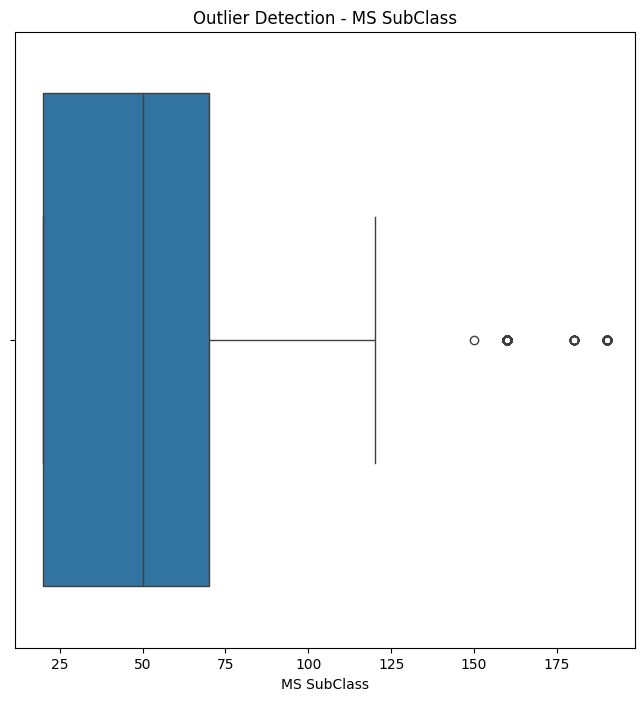

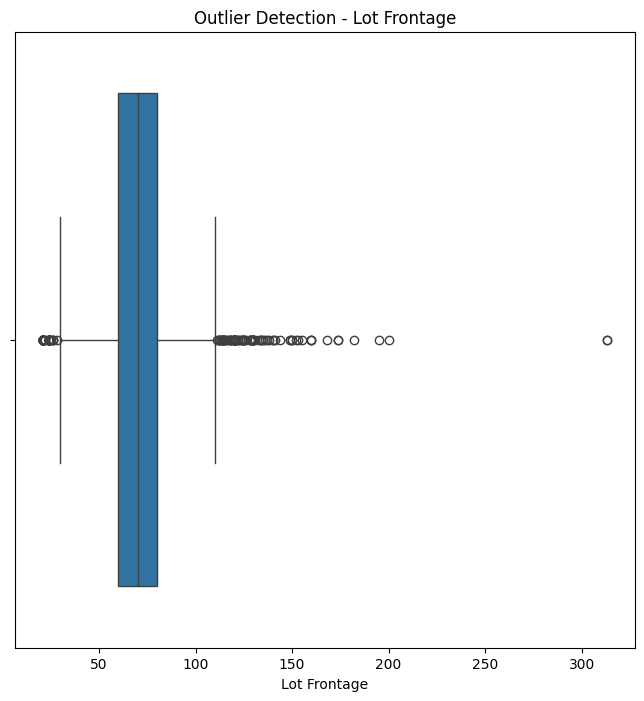

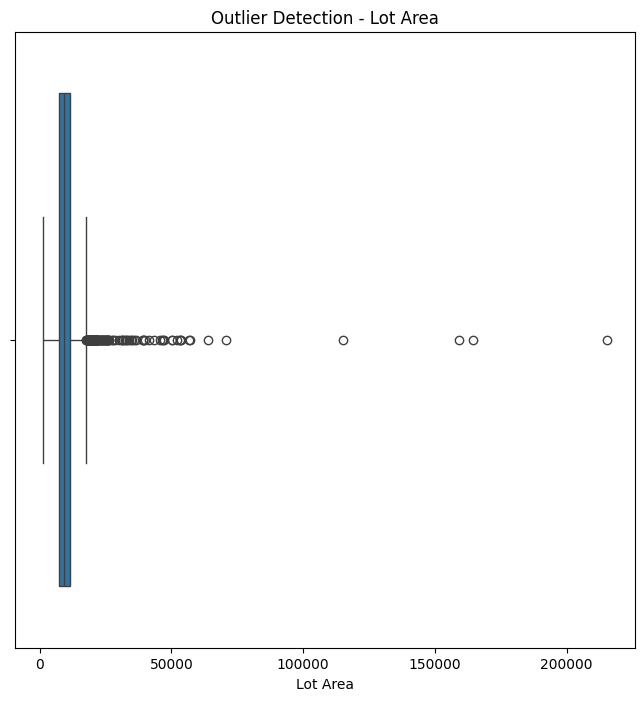

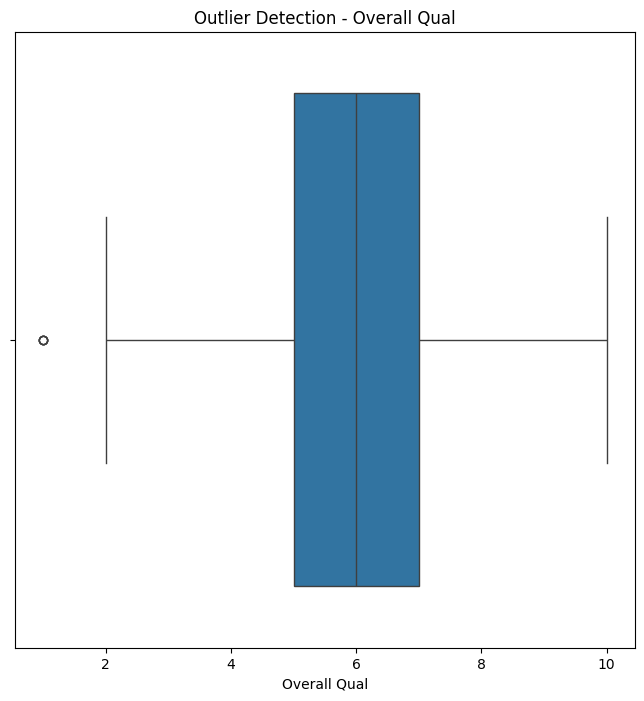

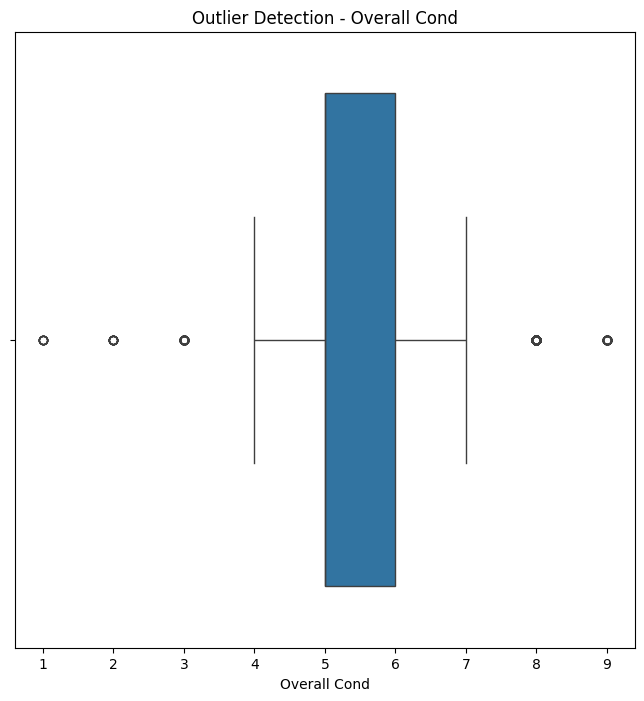

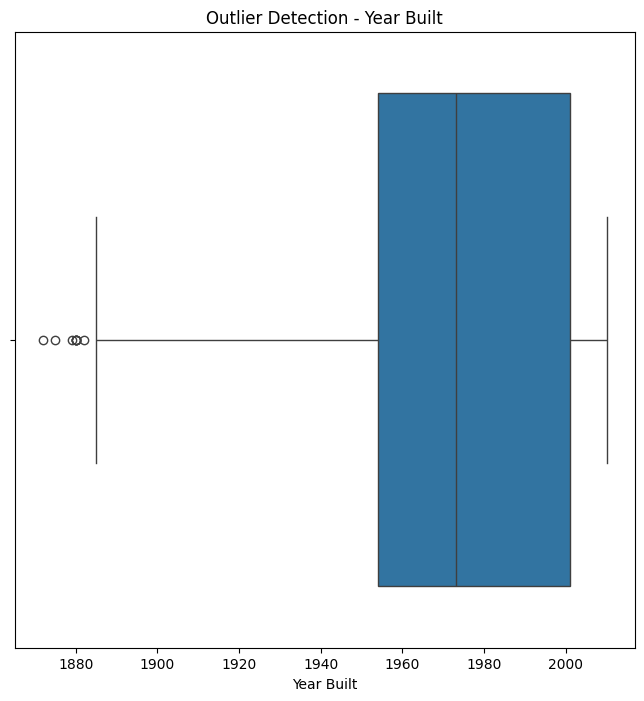

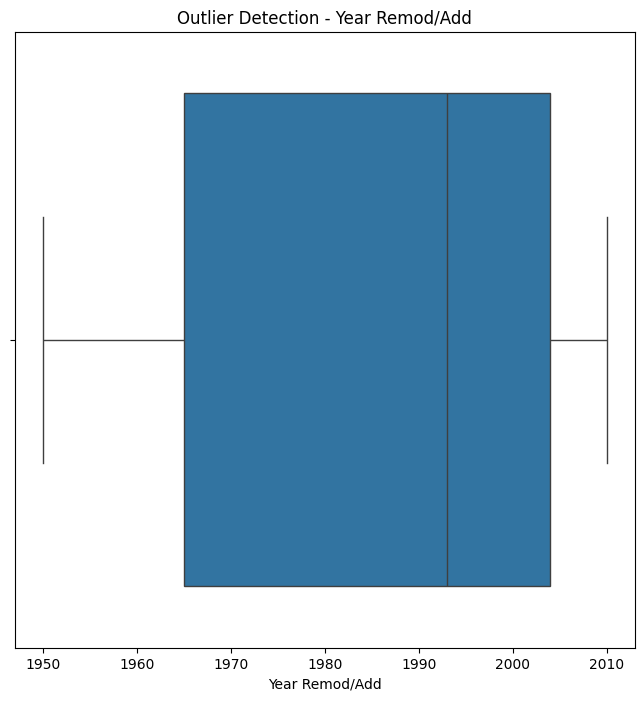

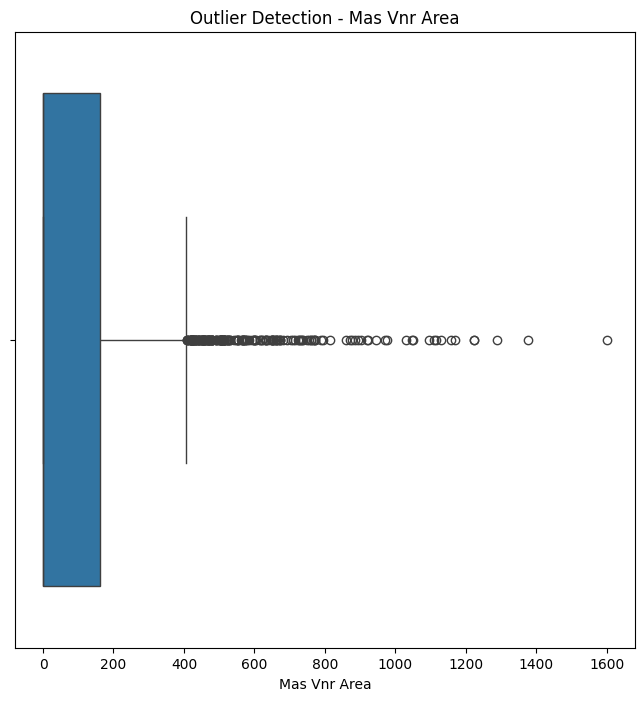

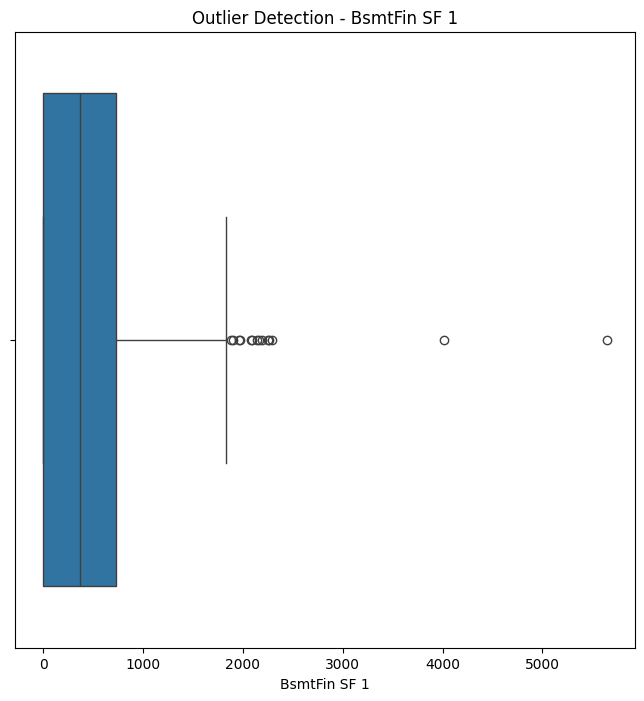

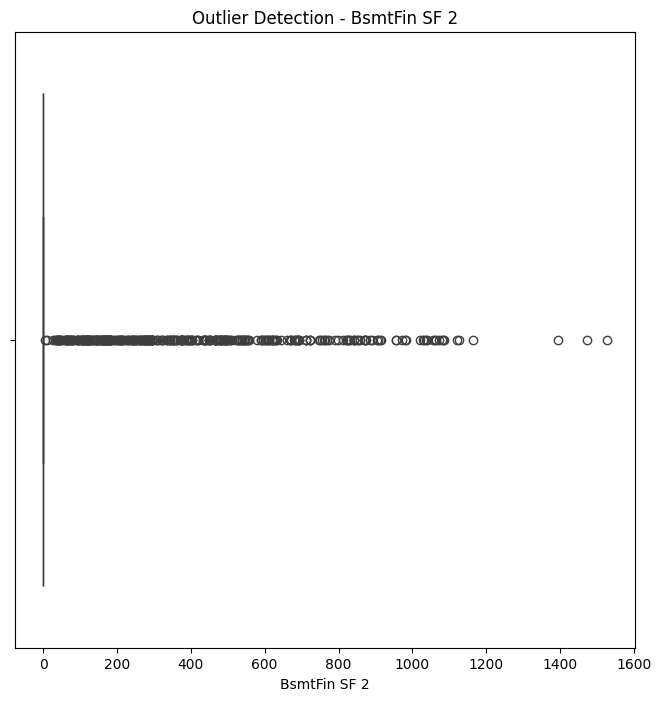

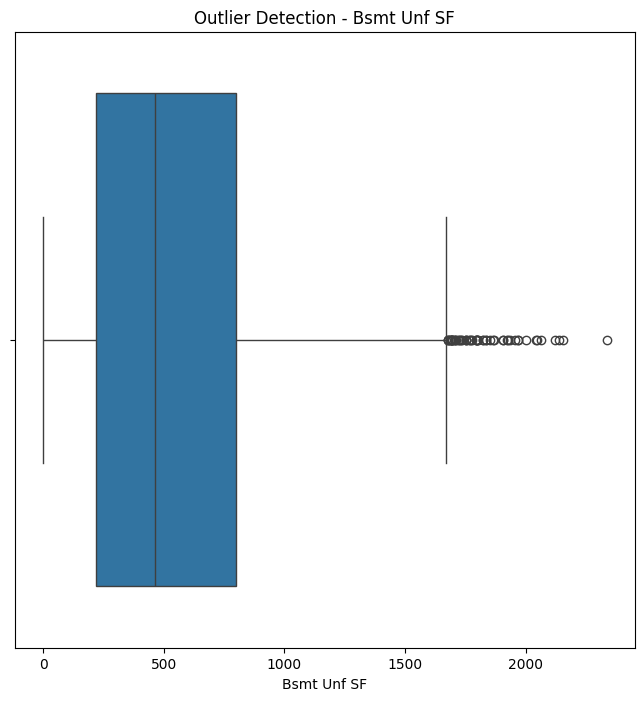

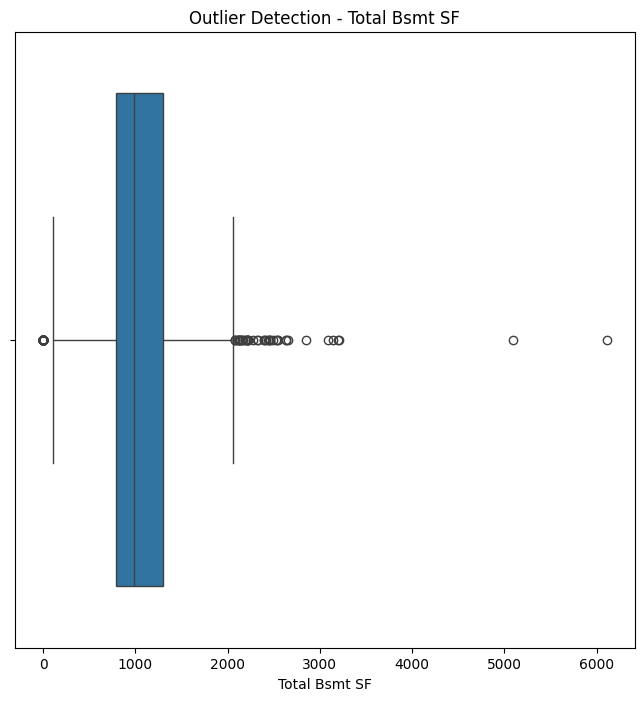

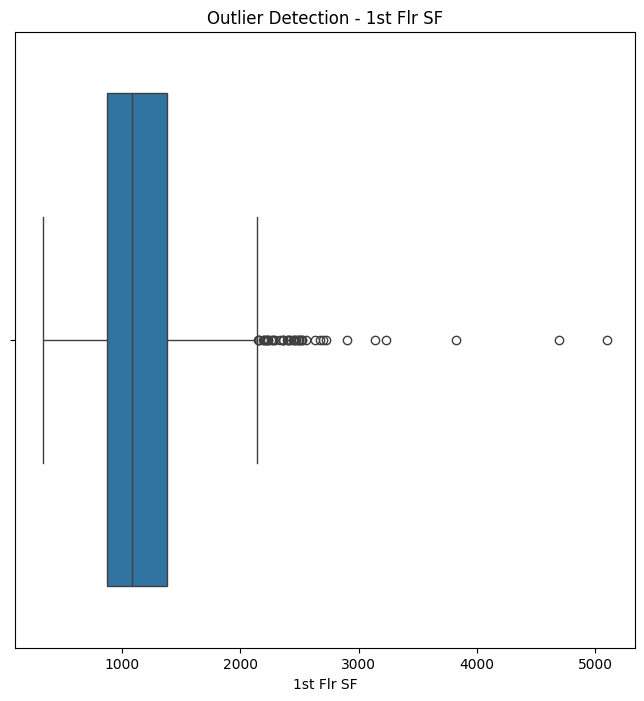

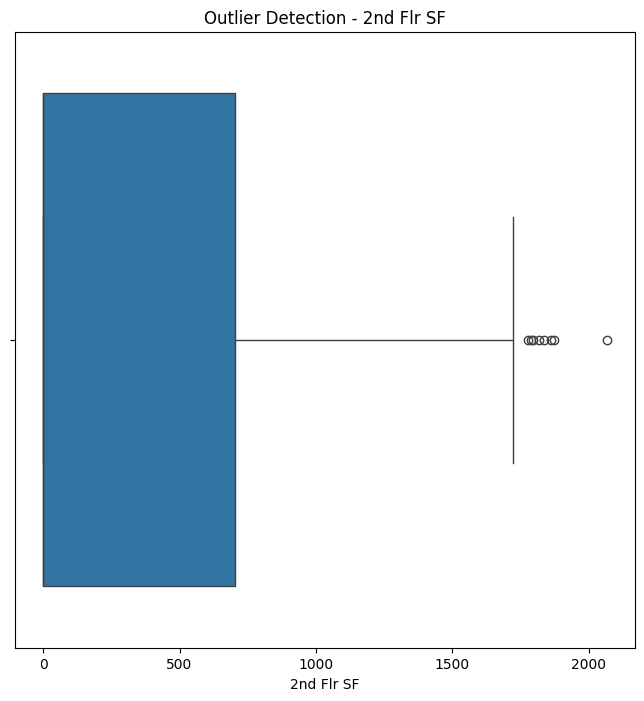

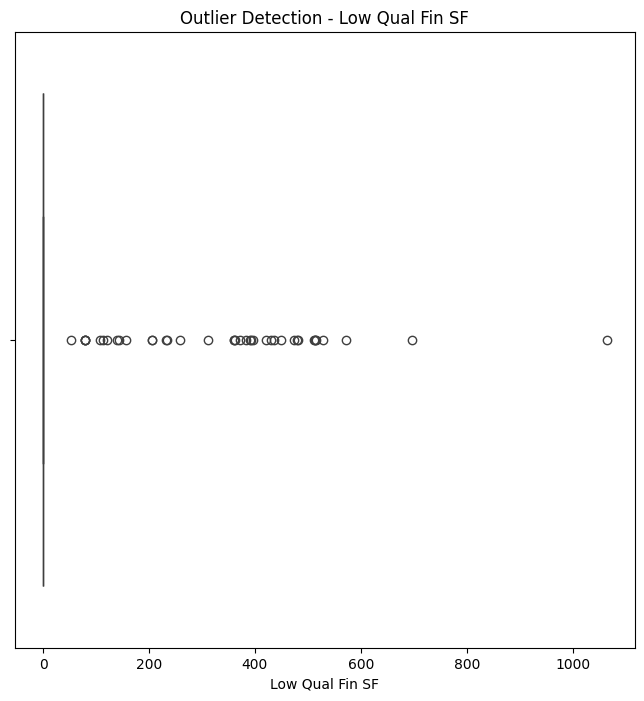

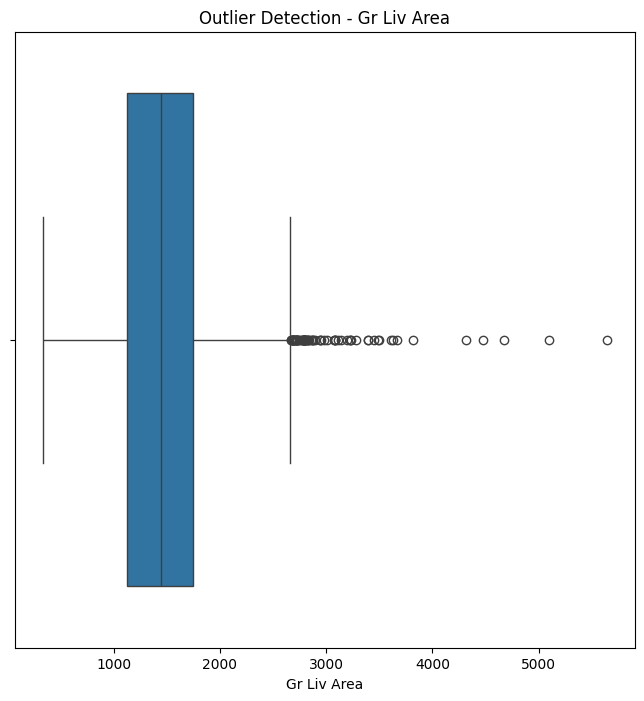

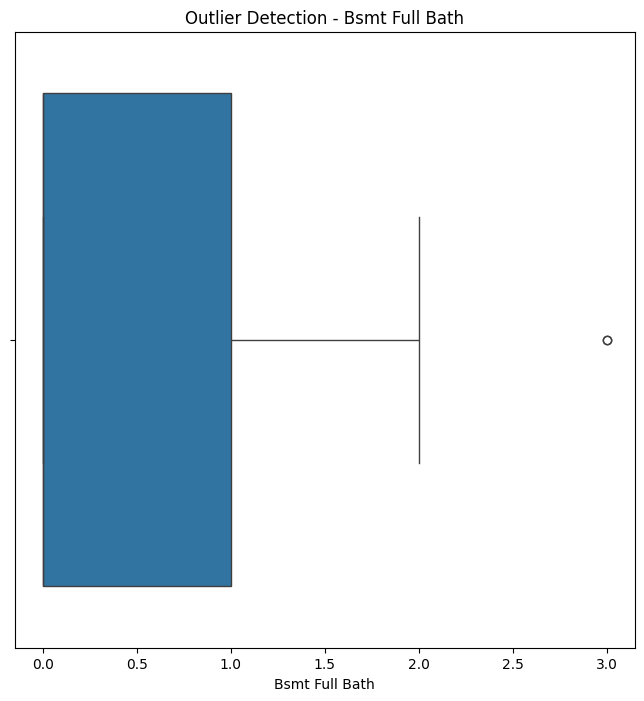

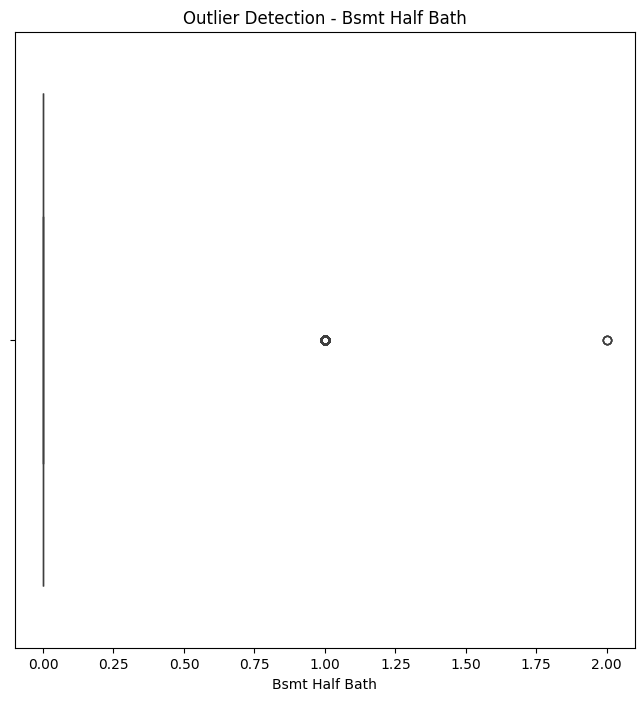

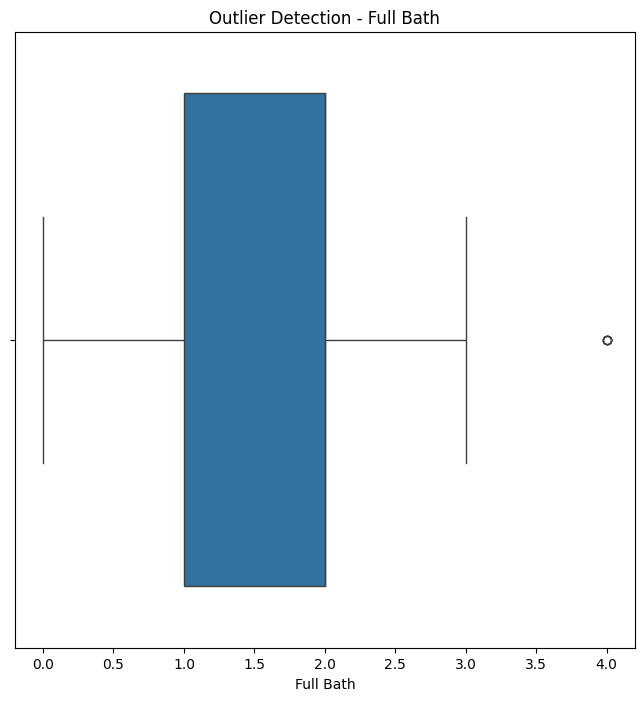

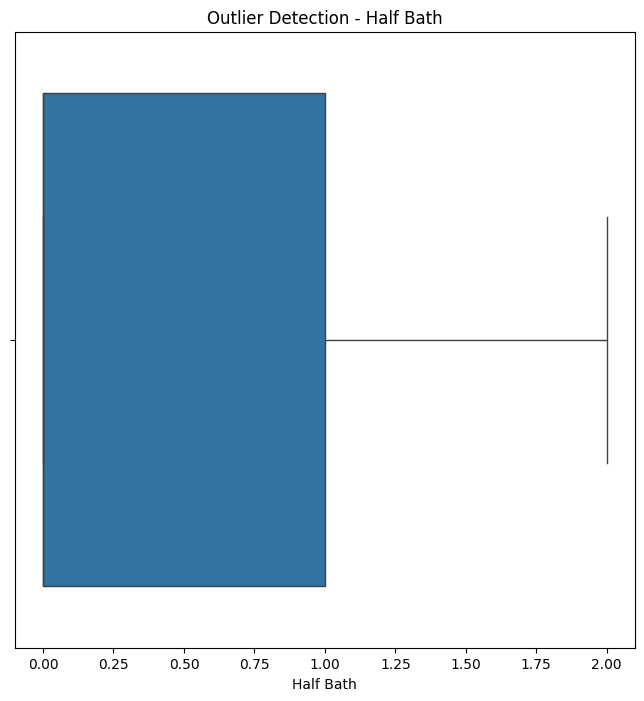

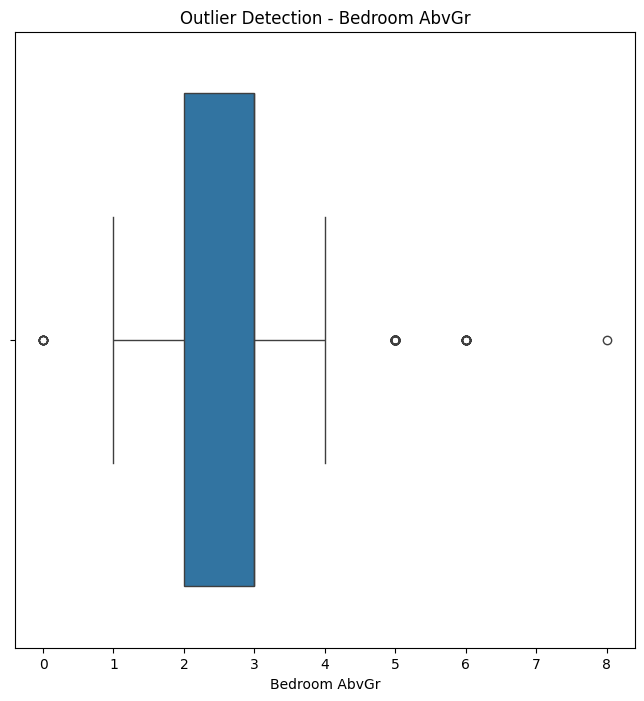

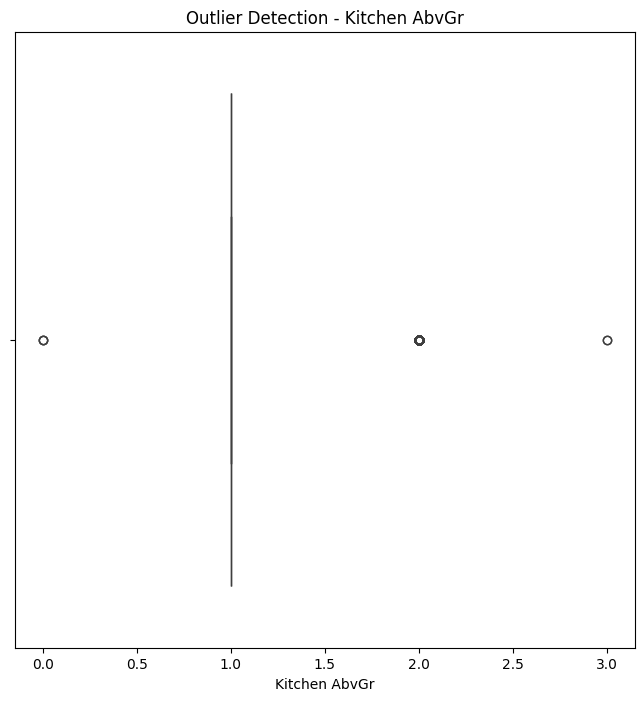

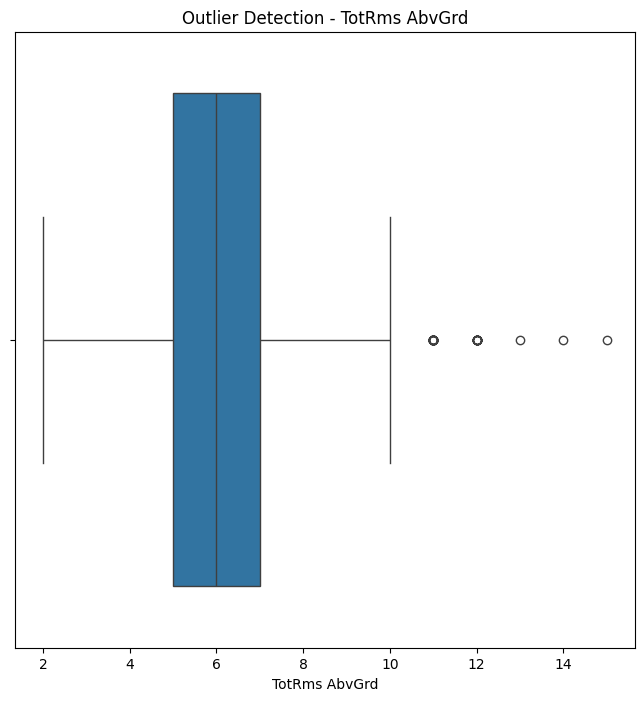

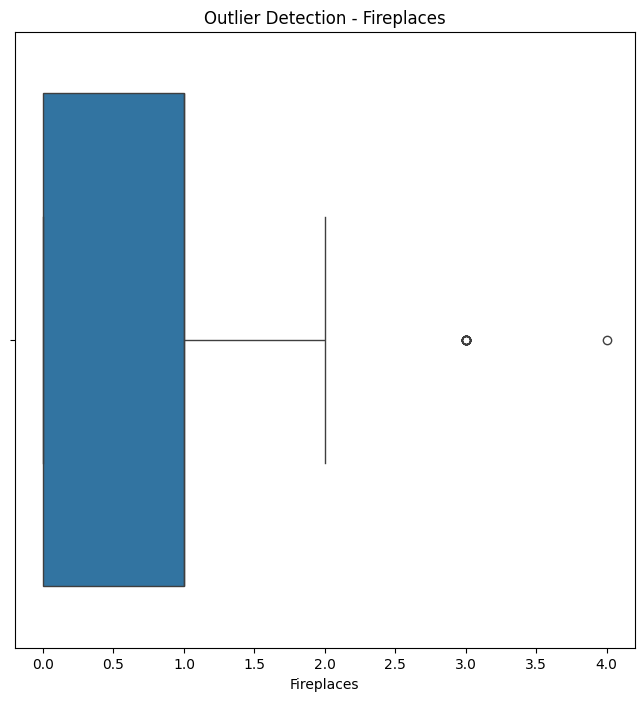

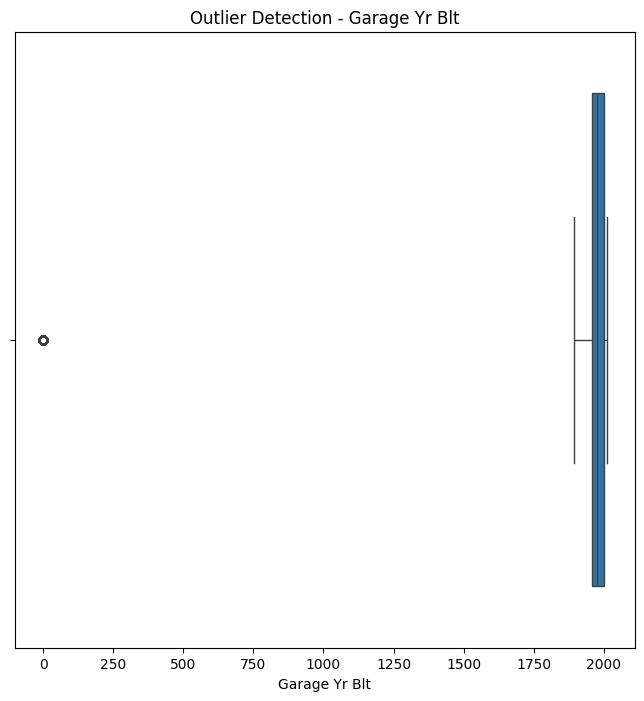

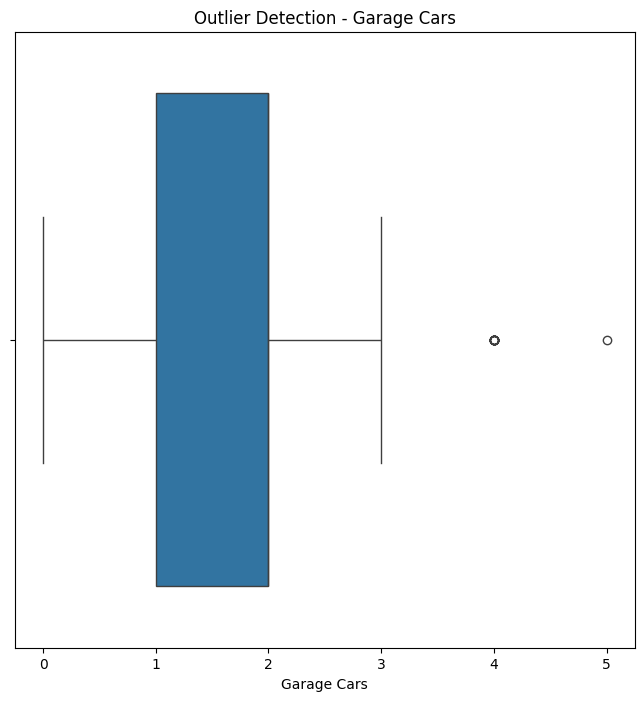

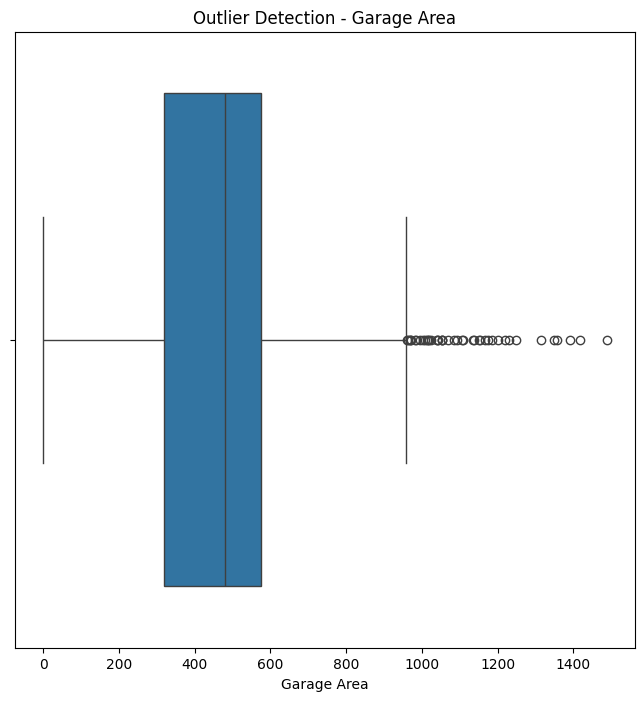

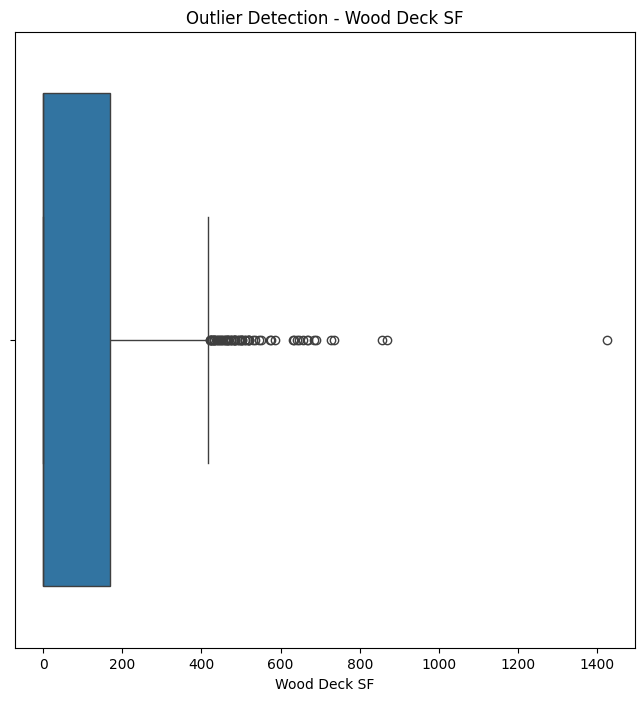

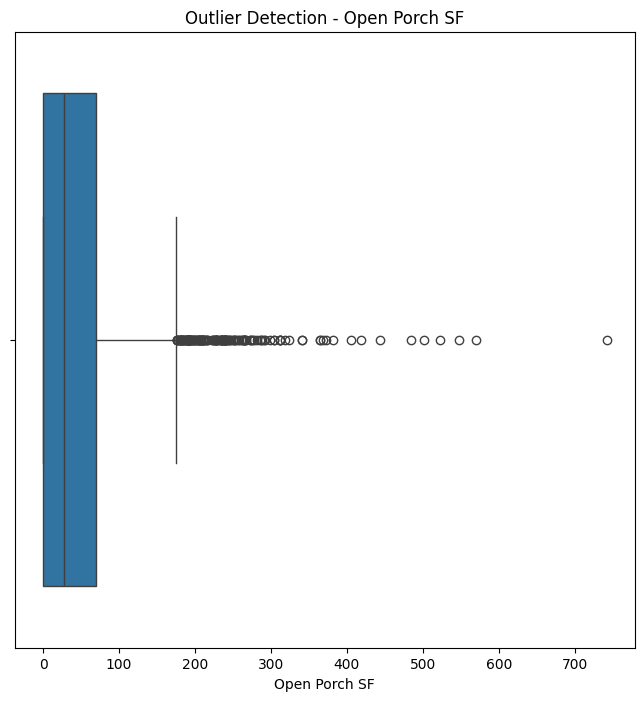

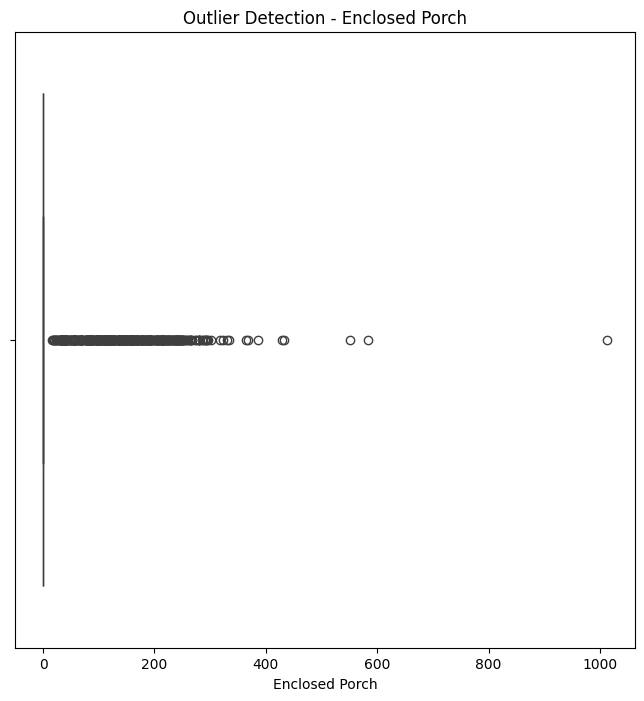

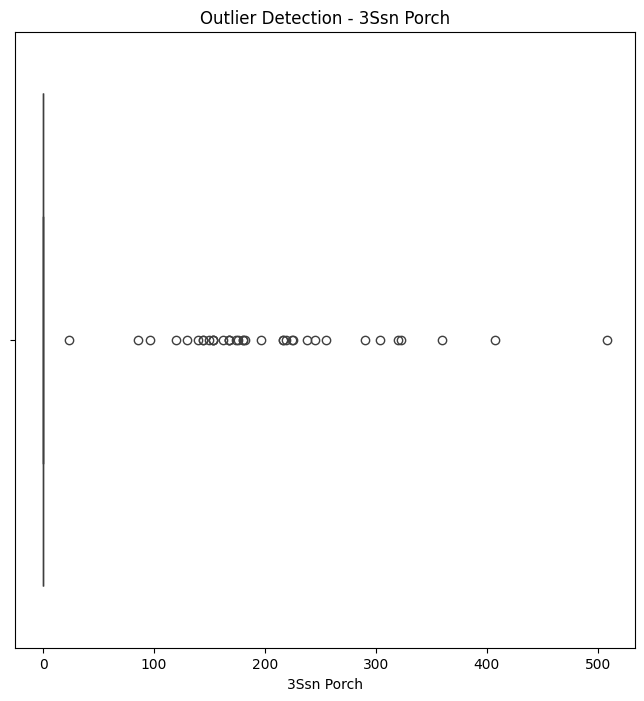

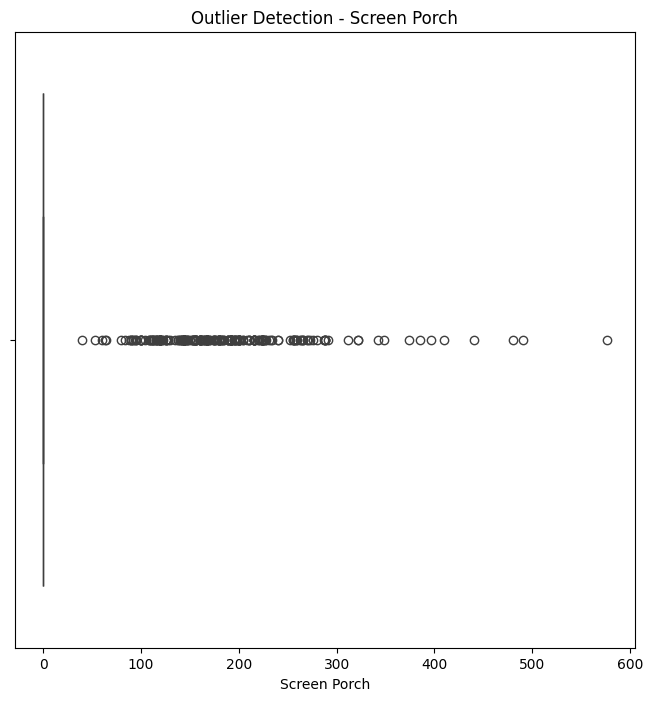

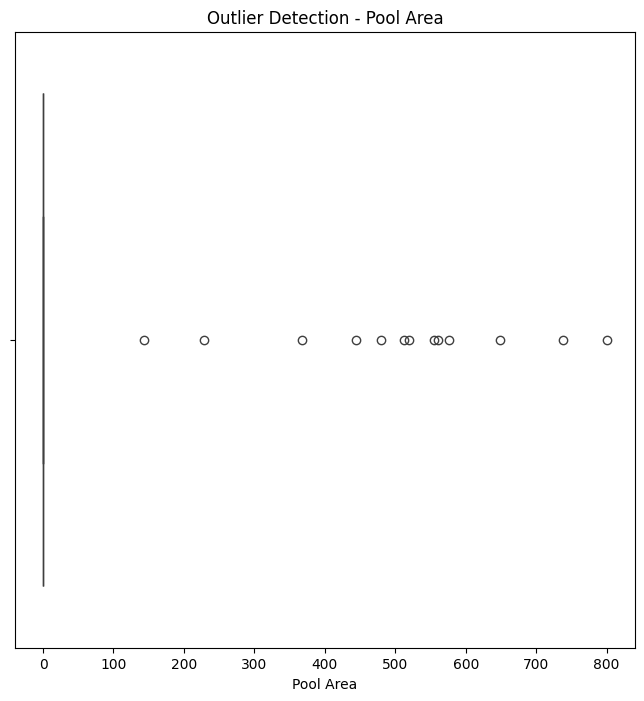

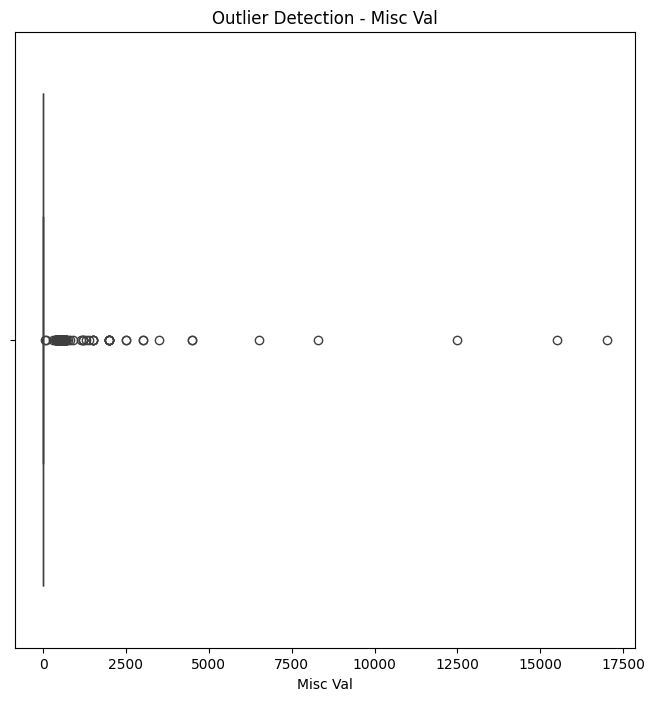

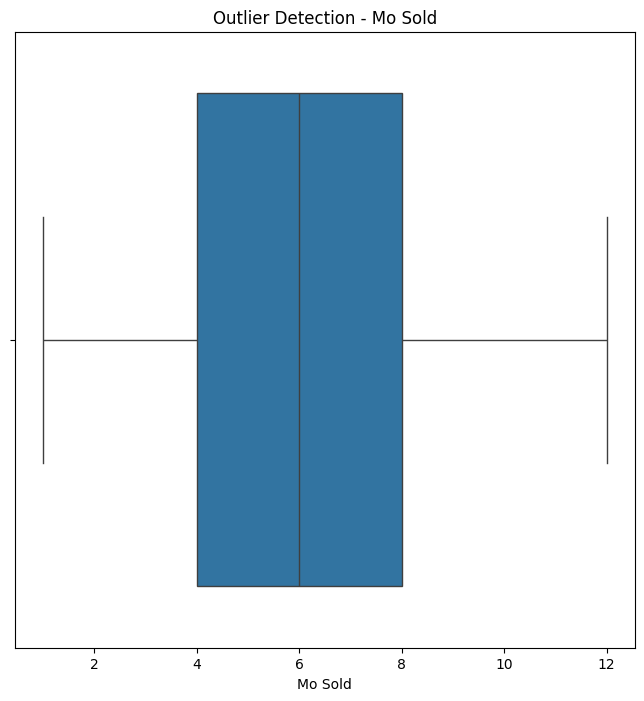

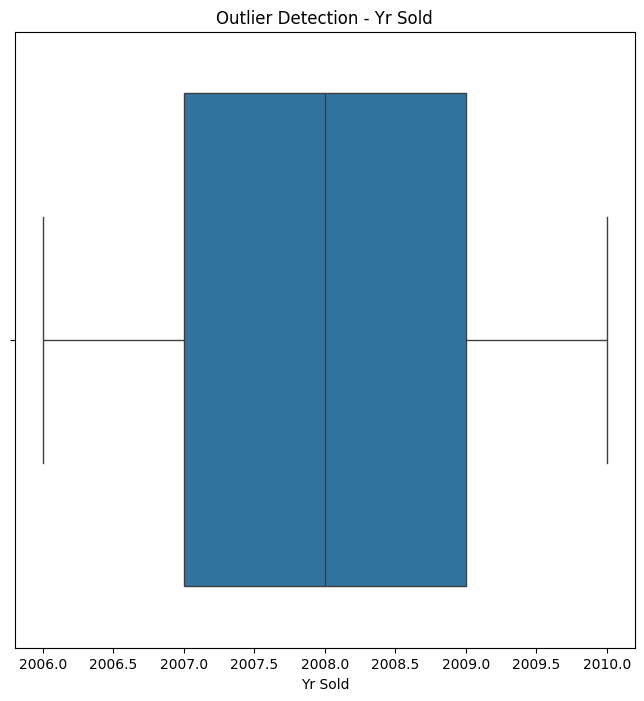

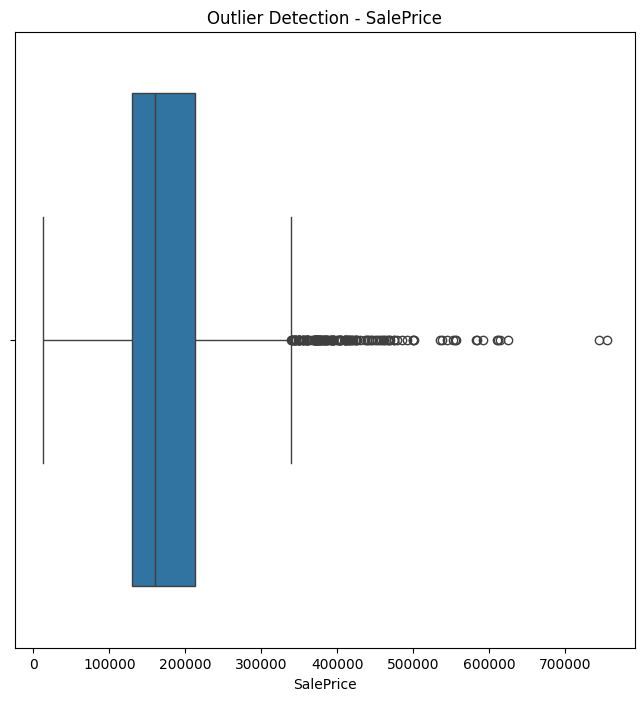

In [64]:
for col in num_col:
    plt.figure(figsize=(8,8))
    sns.boxplot(x=df[col])
    plt.title(f'Outlier Detection - {col}')
    plt.xlabel(col)
    plt.show()

In [65]:
out_class = ['MS SubClass', 'Lot Frontage', 'Lot Area', 'Mas Vnr Area', 'BssmtFin SF 2', 'Mas Vnr Area', 'Bsmt Unf SF', 'Total Bsmt SF', '1st Flr SF', '2nd Flr SF', 'Gr Liv Area', 'Garage Area', 'Wood Deck SF', 'Open Porch SF', 'Enclosed Porch', '3Ssn Porch', 'Screen Porch', 'Pool Area', 'Misc Val', 'SalePrice']

In [66]:
# df.drop(columns={'BsmtFin SF 2','Bsmt Half Bath','Low Qual Fin SF'}, inplace=True)

In [67]:
X = df.select_dtypes(include=np.number)
X = X.dropna()

# Add a constant
X = add_constant(X)

# Calculate VIF
vif_data = pd.DataFrame({
    "Feature": X.columns,
    "VIF": [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
})

# Exclude constant and sort by VIF
vif_data = (
    vif_data[vif_data["Feature"] != "const"]
    .sort_values("VIF", ascending=False)
    .reset_index(drop=True)
)

print(vif_data.round(2))

/tmp/ipykernel_1077/3030476947.py:11: UserWarning: The design matrix is poorly conditioned (condition number=9.10e+15). VIF calculations may be numerically unstable.
  variance_inflation_factor(X.values, i)
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: 

            Feature           VIF
0        1st Flr SF  1.000800e+15
1      BsmtFin SF 2  1.000800e+15
2       Bsmt Unf SF  1.000800e+15
3     Total Bsmt SF  1.000800e+15
4      BsmtFin SF 1  1.000800e+15
5   Low Qual Fin SF  1.000800e+15
6       Gr Liv Area  1.000800e+15
7        2nd Flr SF  1.000800e+15
8       Garage Cars  6.380000e+00
9         SalePrice  6.220000e+00
10      Garage Area  5.610000e+00
11    TotRms AbvGrd  4.450000e+00
12       Year Built  3.940000e+00
13     Overall Qual  3.760000e+00
14        Full Bath  2.800000e+00
15    Bedroom AbvGr  2.380000e+00
16   Year Remod/Add  2.340000e+00
17   Bsmt Full Bath  2.160000e+00
18        Half Bath  2.150000e+00
19    Garage Yr Blt  1.810000e+00
20     Lot Frontage  1.710000e+00
21      MS SubClass  1.710000e+00
22    Kitchen AbvGr  1.610000e+00
23     Overall Cond  1.560000e+00
24       Fireplaces  1.560000e+00
25     Mas Vnr Area  1.450000e+00
26         Lot Area  1.320000e+00
27   Enclosed Porch  1.240000e+00
28     Wood De

/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stat

In [68]:
df.drop(columns={'1st Flr SF','2nd Flr SF','Low Qual Fin SF', 'Gr Liv Area', 'BsmtFin SF 1', 'BsmtFin SF 2', 'Total Bsmt SF', 'Bsmt Unf SF'}, inplace=True, errors='ignore')
print(len(df.columns))

66


In [69]:
corr_with_target = df.corr(numeric_only=True)['SalePrice'].sort_values(ascending=False)
print(corr_with_target)

SalePrice         1.000000
Overall Qual      0.799219
Garage Cars       0.647965
Garage Area       0.640468
Year Built        0.558705
Full Bath         0.545889
Year Remod/Add    0.533108
Mas Vnr Area      0.502481
TotRms AbvGrd     0.495877
Fireplaces        0.474430
Lot Frontage      0.353441
Wood Deck SF      0.327204
Open Porch SF     0.313200
Half Bath         0.285468
Bsmt Full Bath    0.276096
Lot Area          0.266663
Garage Yr Blt     0.253897
Bedroom AbvGr     0.144787
Screen Porch      0.112212
Pool Area         0.068426
Mo Sold           0.034824
3Ssn Porch        0.032243
Misc Val         -0.015537
Yr Sold          -0.030412
Bsmt Half Bath   -0.035803
MS SubClass      -0.084731
Overall Cond     -0.101413
Kitchen AbvGr    -0.119826
Enclosed Porch   -0.128440
Name: SalePrice, dtype: float64


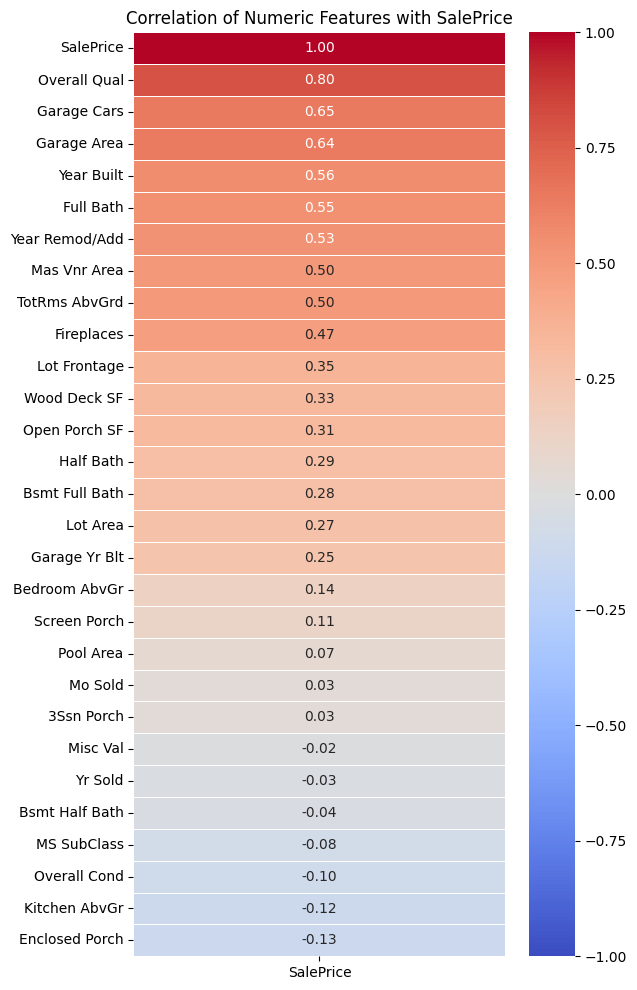

In [70]:
corr_df = corr_with_target.to_frame()

# Set up the matplotlib figure
plt.figure(figsize=(6, 12))

# Draw the heatmap focusing on the correlations with SalePrice
sns.heatmap(
    corr_df,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    fmt=".2f",
    linewidths=0.5
)

plt.title('Correlation of Numeric Features with SalePrice')
plt.show()

In [91]:
selected_features = [
    'Overall Qual',
    'Garage Area',
    'Year Built',
    'Full Bath',
    'Year Remod/Add',
    'Mas Vnr Area',
    'TotRms AbvGrd',
    'Fireplaces',
    'Garage Cars',
    'Lot Frontage'

]

X = df[selected_features]
y = df['SalePrice']

In [115]:
X_scaled = StandardScaler().fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)
X_scaled

,Overall Qual,Garage Area,Year Built,Full Bath,Year Remod/Add,Mas Vnr Area,TotRms AbvGrd,Fireplaces,Garage Cars,Lot Frontage
0,-0.067335,0.256279,-0.376335,-1.023452,-1.162300,0.060244,0.354268,2.161056,0.306418,3.292238
1,-0.776042,1.195355,-0.343236,-1.023452,-1.114363,-0.566550,-0.916840,-0.925715,-1.008213,0.484442
2,-0.067335,-0.747882,-0.442532,-1.023452,-1.258174,0.037859,-0.281286,-0.925715,-1.008213,0.530471
3,0.641373,0.228385,-0.111546,0.784894,-0.778804,-0.566550,0.989822,2.161056,0.306418,1.082825
4,-0.776042,0.042429,0.848312,0.784894,0.659306,-0.566550,-0.281286,0.617671,0.306418,0.208265
...,...,...,...,...,...,...,...,...,...,...
2921,-0.067335,0.535212,0.418030,-1.023452,-0.011812,-0.566550,-0.281286,-0.925715,0.306418,-1.494825
2922,-0.776042,0.051727,0.384932,-1.023452,-0.059749,-0.566550,-0.916840,-0.925715,0.306418,0.208265
2923,-0.776042,-2.198336,0.682819,-1.023452,0.371684,-0.566550,-0.281286,-0.925715,-2.322844,-0.344088
2924,-0.776042,-0.255100,0.087045,-1.023452,-0.443245,-0.566550,-0.281286,0.617671,0.306418,0.346354


In [201]:
x_train, x_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

In [202]:
model_lr = LinearRegression()
model_lr.fit(x_train, y_train)

pred_lr = model_lr.predict(x_test)

print(f'R2 Score: {(round(r2_score(y_test, pred_lr),2))}')
print(f'MSE: {mean_squared_error(y_test, pred_lr)}')
print(f'RMSE: {root_mean_squared_error(y_test,pred_lr)}')

R2 Score: 0.8
MSE: 1444382574.0059674
RMSE: 38005.03353512489


In [203]:
model_dt = DecisionTreeRegressor(random_state=42,max_depth=5)
model_dt.fit(x_train, y_train)

pred_dt = model_dt.predict(x_test)

print(f'R2 Score: {(round(r2_score(y_test, pred_dt),2))}')
print(f'MSE: {mean_squared_error(y_test, pred_dt)}')
print(f'RMSE: {root_mean_squared_error(y_test,pred_dt)}')

R2 Score: 0.8
MSE: 1456012297.2921488
RMSE: 38157.72919464874


In [204]:
model_rf = RandomForestRegressor(random_state=42, n_estimators=400, max_depth=8)
model_rf.fit(x_train, y_train)

pred_rf = model_rf.predict(x_test)

print(f'R2 Score: {(round(r2_score(y_test, pred_rf),2))}')
print(f'MSE: {mean_squared_error(y_test, pred_rf)}')
print(f'RMSE: {root_mean_squared_error(y_test,pred_rf)}')

R2 Score: 0.86
MSE: 1015373752.783771
RMSE: 31864.929825495787


In [205]:
model_xg = XGBRegressor(random_state=42, n_estimators=200, max_depth=2, eval_metric="rmse", early_stopping_rounds=3)
model_xg.fit(x_train, y_train, verbose=False, eval_set=[(x_train, y_train), (x_test, y_test)])

pred_xg = model_xg.predict(x_test)

print(f'R2 Score: {(round(r2_score(y_test, pred_xg),2))}')
print(f'MSE: {mean_squared_error(y_test, pred_xg)}')
print(f'RMSE: {root_mean_squared_error(y_test,pred_xg)}')

R2 Score: 0.86
MSE: 1004298624.0
RMSE: 31690.671875


In [244]:
model_cb = CatBoostRegressor(iterations=500, depth=7, learning_rate=0.05, loss_function='RMSE', random_seed=42, verbose=False)

model_cb.fit(x_train, y_train)

pred_cb = model_cb.predict(x_test)

print("R²:", round(r2_score(y_test, pred_cb),2))
print("MAE:", mean_absolute_error(y_test, pred_cb))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred_cb)))

R²: 0.88
MAE: 20088.56744372202
RMSE: 29674.47981017491


In [245]:
# We will use the trained CatBoost model and selected features
# selected_features = ['Overall Qual', 'Garage Area', 'Year Built', 'Full Bath', 'Year Remod/Add', 'Mas Vnr Area', 'TotRms AbvGrd', 'Fireplaces', 'Garage Cars', 'Lot Frontage']

# Extract valid ranges and options from the dataset to guide the user
guide_info = {}
for feature in selected_features:
    min_val = float(df[feature].min())
    max_val = float(df[feature].max())
    median_val = float(df[feature].median())
    unique_count = df[feature].nunique()

    if unique_count <= 15:
        options = sorted(list(df[feature].unique()))
        guide_info[feature] = {
            'type': 'discrete',
            'options': options,
            'default': median_val
        }
    else:
        guide_info[feature] = {
            'type': 'continuous',
            'min': min_val,
            'max': max_val,
            'default': median_val
        }

print("=== HOUSE PRICE PREDICTION SYSTEM ===\n")
print("Please provide the values for the following features.")
print("Leave the input blank to use the default (median) value shown in brackets.\n")

user_inputs = {}
for feature, info in guide_info.items():
    if info['type'] == 'discrete':
        options_str = ", ".join(map(str, info['options']))
        prompt = f"{feature} (Options: [{options_str}] | Default: {info['default']}): "
    else:
        prompt = f"{feature} (Range: {info['min']} to {info['max']} | Default: {info['default']}): "

    user_val = input(prompt).strip()

    if user_val == "":
        user_inputs[feature] = info['default']
    else:
        try:
            user_inputs[feature] = float(user_val)
        except ValueError:
            print(f"Invalid input. Using default value: {info['default']}")
            user_inputs[feature] = info['default']

# Convert user inputs to DataFrame
input_df = pd.DataFrame([user_inputs])

# Scale the input features using the same scaler parameters as training
scaler = StandardScaler()
scaler.fit(df[selected_features])
input_scaled = scaler.transform(input_df)

# Predict using our best model (CatBoost)
predicted_price = model_cb.predict(input_scaled)[0]

print("\n===============================")
print("         PREDICTION RESULT       ")
print("===============================")
for feat, val in user_inputs.items():
    print(f"{feat}: {val}")
print("-------------------------------")
print(f"Estimated House Value (CatBoost): ${predicted_price:,.2f}")
print("===============================")

=== HOUSE PRICE PREDICTION SYSTEM ===

Please provide the values for the following features.
Leave the input blank to use the default (median) value shown in brackets.

Overall Qual (Options: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10] | Default: 6.0): 8
Garage Area (Range: 0.0 to 1488.0 | Default: 480.0): 345
Year Built (Range: 1872.0 to 2010.0 | Default: 1973.0): 200
Full Bath (Options: [0, 1, 2, 3, 4] | Default: 2.0): 4
Year Remod/Add (Range: 1950.0 to 2010.0 | Default: 1993.0): 2004
Mas Vnr Area (Range: 0.0 to 1600.0 | Default: 0.0): 1500
TotRms AbvGrd (Options: [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15] | Default: 6.0): 15
Fireplaces (Options: [0, 1, 2, 3, 4] | Default: 1.0): 3
Garage Cars (Options: [0.0, 1.0, 2.0, 3.0, 4.0, 5.0] | Default: 2.0): 4
Lot Frontage (Range: 21.0 to 313.0 | Default: 70.0): 234

         PREDICTION RESULT       
Overall Qual: 8.0
Garage Area: 345.0
Year Built: 200.0
Full Bath: 4.0
Year Remod/Add: 2004.0
Mas Vnr Area: 1500.0
TotRms AbvGrd: 15.0
Fireplaces: 3.0


In [247]:
# Calculate metrics for each model based on their predictions
models_metrics = {
    'Linear Regression': {
        'R2 Score': r2_score(y_test, pred_lr),
        'MSE': mean_squared_error(y_test, pred_lr),
        'RMSE': root_mean_squared_error(y_test, pred_lr)
    },
    'Decision Tree': {
        'R2 Score': r2_score(y_test, pred_dt),
        'MSE': mean_squared_error(y_test, pred_dt),
        'RMSE': root_mean_squared_error(y_test, pred_dt)
    },
    'Random Forest': {
        'R2 Score': r2_score(y_test, pred_rf),
        'MSE': mean_squared_error(y_test, pred_rf),
        'RMSE': root_mean_squared_error(y_test, pred_rf)
    },
    'XGBoost': {
        'R2 Score': r2_score(y_test, pred_xg),
        'MSE': mean_squared_error(y_test, pred_xg),
        'RMSE': root_mean_squared_error(y_test, pred_xg)
    },
    'CatBoost': {
        'R2 Score': r2_score(y_test, pred_cb),
        'MSE': mean_squared_error(y_test, pred_cb),
        'RMSE': root_mean_squared_error(y_test, pred_cb)
    }
}

# Convert metrics dictionary to a DataFrame
comparison_df = pd.DataFrame(models_metrics).T
comparison_df['R2 Score'] = comparison_df['R2 Score'].round(2)
comparison_df['MSE'] = comparison_df['MSE'].round(2)
comparison_df['RMSE'] = comparison_df['RMSE'].round(2)

print("=========================================================")
print("                  MODEL LEADERBOARD                      ")
print("=========================================================")
print(comparison_df.to_string())
print("=========================================================\n")

# Identify the best model based on the lowest RMSE
best_model_name = comparison_df['RMSE'].idxmin()
best_model_rmse = comparison_df.loc[best_model_name, 'RMSE']
best_model_r2 = comparison_df.loc[best_model_name, 'R2 Score']

print(f"★ BEST MODEL: {best_model_name} ★")
print(f"- Lowest RMSE: ${best_model_rmse:,.2f}")
print(f"- R2 Score: {best_model_r2}")

                  MODEL LEADERBOARD                      
                   R2 Score           MSE      RMSE
Linear Regression      0.80  1.444383e+09  38005.03
Decision Tree          0.80  1.456012e+09  38157.73
Random Forest          0.86  1.015374e+09  31864.93
XGBoost                0.86  1.004299e+09  31690.67
CatBoost               0.88  8.805748e+08  29674.48

★ BEST MODEL: CatBoost ★
- Lowest RMSE: $29,674.48
- R2 Score: 0.88
